# Simulate damped acoustic waves (the telegraph equation)

The wave equation with a damping, `p_tt + eta p_t = c^2 laplace(p)`: the field's own first time derivative next to `p.dt2`, which the DSL takes centred in time. This is the telegraph equation; the damping lowers the amplitude by `exp(-eta t / 2)` and leaves a diffusive wake behind the front. Two shots run as one batch, eta = 0 on the left and eta = 0.03 on the right, drawn on one colour scale. Units are dimensionless (grid spacing 1, c = 1).

In [1]:
import base64

import numpy as np
import sympy
import torch
from IPython.display import HTML

from sweep.propagator.options import EagerOptions, Full
from sweep.propagator.torch import PropTorch
from sweep.symbolic import PDE, Coefficient, Eq, Field, Model, laplace

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.allow_tf32 = False                 # full fp32 stencils
opts = EagerOptions(use_compile=False)

Helpers: a Ricker wavelet, a run that keeps snapshots, and a GIF writer.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


def ricker(nt, dt, f0):
    a = (np.pi * f0 * (np.arange(nt) * dt - 1.5 / f0)) ** 2
    return torch.tensor((1 - 2 * a) * np.exp(-a), dtype=torch.float32)


def snapshots(solver, wavelet, sources, receivers, models, every=10, **kwargs):
    """Run one batch; return the record, every field every `every` steps (cropped to the model) and the times."""
    steps = list(range(every - 1, solver.nt, every))
    with torch.no_grad():
        record, snap = solver(wavelet, sources, receivers, models=models, return_wavefield=True,
                              snapshot_times=steps, **kwargs)
    nz, nx = models[0].shape[-2:]
    x0, _, z0, _ = solver._runtime_padding()
    if snap.shape[-2] - nz < z0 or snap.shape[-1] - nx < x0:   # padding not as reported: centre the crop
        z0, x0 = (snap.shape[-2] - nz) // 2, (snap.shape[-1] - nx) // 2
    snap = snap[..., z0:z0 + nz, x0:x0 + nx]
    names = [f.name for f in solver.equation.field_specs]
    frames = {n: snap[:, i, :, 0].numpy() for i, n in enumerate(names) if not n.startswith("_")}
    return record.cpu(), frames, (np.array(steps) + 1) * float(solver.dt)


def save_gif(path, panels, times, extent, xlabel="x (km)", ylabel="z (km)", unit="s", cmap="seismic",
             clip=99.8, outline=None, normalize=False, share=False):
    """Animate panels [(title, frames (nframe, nz, nx))] with fixed colour limits; outline: a model drawn as contours;
    share: one colour scale for every panel."""
    aspect = abs(extent[1] - extent[0]) / abs(extent[2] - extent[3])
    fig, axes = plt.subplots(1, len(panels), figsize=((3.2 * aspect + 0.45) * len(panels), 3.6),
                             squeeze=False, constrained_layout=True)
    outlines = outline if isinstance(outline, list) else [outline] * len(panels)
    images = []
    for k, (ax, (title, data), line) in enumerate(zip(axes[0], panels, outlines)):
        if normalize:
            data = data / np.abs(data).max(axis=(1, 2), keepdims=True).clip(min=1e-30)
        if cmap == "seismic":
            a = np.percentile(np.abs(np.stack([d for _, d in panels]) if share else data), clip) or 1.0
            lo, hi = -a, a
        else:
            lo, hi = np.percentile(data, [100 - clip, clip])
        im = ax.imshow(data[0], cmap=cmap, vmin=lo, vmax=hi, extent=extent, interpolation="bilinear")
        if line is not None:
            ax.contour(line, levels=6, colors="k", linewidths=0.5, alpha=0.35, extent=extent, origin="upper")
        ax.set(title=title, xlabel=xlabel)
        if k == 0:
            ax.set_ylabel(ylabel)
        else:
            ax.tick_params(labelleft=False)
        images.append((im, data))
    clock = fig.suptitle("")

    def draw(i):
        for im, data in images:
            im.set_data(data[i])
        clock.set_text(f"t = {times[i]:.3g} {unit}")

    FuncAnimation(fig, draw, frames=len(times)).save(path, writer=PillowWriter(fps=10), dpi=70)
    plt.close(fig)
    return path


def show_gif(path):
    """Show a GIF inline; as HTML, so the docs site renders it too."""
    data = base64.b64encode(open(path, "rb").read()).decode()
    return HTML(f'<img src="data:image/gif;base64,{data}">')

## The PDE

Declare the models and fields, write one equation per field, and build the equation class.

In [3]:
c, eta = Model("c"), Model("eta")
p = Field("p", source=True, receiver=True)

pde = PDE([Eq(p.dt2 + eta * p.dt, c**2 * laplace(p))], name="Telegraph")
Telegraph = pde.build(ndim=2)
pde

PDE([Eq(eta*p.dt + p.dt2, c**2*laplace(p))], name='Telegraph')

## Run it

A model, a propagator, one batch of shots; a snapshot of every field is kept at regular steps.

In [4]:
n, h, dt, nt, f0 = 241, 1.0, 0.3, 480, 0.05
c_b = torch.ones(2, n, n, device=dev)
eta_b = torch.stack([torch.zeros(n, n), torch.full((n, n), 0.03)]).to(dev)

solver = PropTorch(Telegraph(8, device=dev), shape=(n, n), dh=h, dt=dt, nt=nt, dev=dev,
                   impl="eager", memory=Full(), eager_options=opts)
src = np.array([[n // 2, n // 2]] * 2)
rec = np.array([[[n // 2, n // 2]]] * 2)
record, frames, t = snapshots(solver, ricker(nt, dt, f0), src, rec, [c_b, eta_b], every=12,
                              max_vel=1.0, pml_freq=f0)

## The wavefield


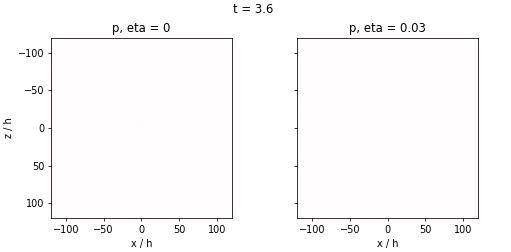

In [5]:
r = (n - 1) * h / 2
ext = [-r, r, r, -r]
gif = save_gif("83_symbolic_damped_acoustic.gif", [("p, eta = 0", frames["p"][:, 0]),
                                                   ("p, eta = 0.03", frames["p"][:, 1])],
               t, ext, xlabel="x / h", ylabel="z / h", unit="", share=True)
show_gif(gif)